# Swat River / KPK flood dataset

Three small files from Kaggle (https://www.kaggle.com/datasets/mmumairkhattak/swat-kpk-flood-dataset): a daily hydro-met series, a yearly flood table and a four-row table of sub-basin features.

The README shipped with the data calls it a synthetic dataset "engineered based on historical reports". So the daily series is simulated, not gauge observations. Everything below describes the generated numbers, not the real Swat River.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.05)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
charts = Path("charts")
charts.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(charts / name, dpi=150, bbox_inches="tight")
    plt.show()

## Loading and first look

In [2]:
daily_raw = pd.read_csv("daily_hydro_met.csv")
floods = pd.read_csv("historical_floods.csv")
basin = pd.read_csv("basin_geospatial_features.csv")

for name, d in [("daily", daily_raw), ("floods", floods), ("basin", basin)]:
    print(name, d.shape)
daily_raw.head()

daily (975, 7)
floods (17, 5)
basin (4, 5)


,Date,Station,Daily_Rainfall_mm,Avg_Temperature_C,River_Discharge_Cusecs,Water_Level_Meters,Flood_Label
0,2024-01-01,Chakdara_Gauge,0.939,19.518,"8,922.808",2.278,0
1,2024-01-02,Chakdara_Gauge,6.020,18.849,"9,701.239",2.294,0
2,2024-01-03,Chakdara_Gauge,2.633,19.395,"10,120.628",2.302,0
3,2024-01-04,Chakdara_Gauge,1.826,22.022,"10,180.028",2.304,0
4,2024-01-05,Chakdara_Gauge,0.339,22.126,"10,184.153",2.304,0


In [3]:
daily_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 975 entries, 0 to 974
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Date                    975 non-null    str    
 1   Station                 975 non-null    str    
 2   Daily_Rainfall_mm       975 non-null    float64
 3   Avg_Temperature_C       975 non-null    float64
 4   River_Discharge_Cusecs  975 non-null    float64
 5   Water_Level_Meters      975 non-null    float64
 6   Flood_Label             975 non-null    int64  
dtypes: float64(4), int64(1), str(2)
memory usage: 53.4 KB


In [4]:
floods

,Year,Peak_Discharge_Cusecs,Monsoon_Rainfall_Anomaly_Pct,Flood_Occurred,Damages_PKR_Millions
0,2010,175000,45,1,12000
1,2011,45000,-5,0,0
2,2012,52000,2,0,0
3,2013,48000,-1,0,0
4,2014,55000,5,0,150
5,2015,60000,8,0,200
6,2016,85000,15,0,450
7,2017,40000,-12,0,0
8,2018,42000,-8,0,0
9,2019,50000,4,0,50


In [5]:
basin

,Sub_Basin,Elevation_Mean_m,Avg_Slope_Degrees,Forest_Cover_Pct,Encroachment_Index_1to10
0,Upper Swat (Kalam),2500,32,35,2
1,Mid Swat (Madyan/Bahrain),1600,24,22,5
2,Lower Swat (Mingora),950,12,11,9
3,Chakdara Downstream,680,5,6,7


The flood table is one row per year, 2010 to 2026 (17 rows), and the basin table is four sub-basins. Both are too small for anything beyond describing them. The daily file is where the volume is.

## Profiling the daily file

In [6]:
print("missing values:\n", daily_raw.isna().sum())
print("\nfull duplicate rows:", daily_raw.duplicated().sum())
print("duplicate dates:", daily_raw["Date"].duplicated().sum())
print("\nstations:", daily_raw["Station"].value_counts().to_dict())
print("flood label counts:", daily_raw["Flood_Label"].value_counts().to_dict())

missing values:
 Date                      0
Station                   0
Daily_Rainfall_mm         0
Avg_Temperature_C         0
River_Discharge_Cusecs    0
Water_Level_Meters        0
Flood_Label               0
dtype: int64

full duplicate rows: 0
duplicate dates: 0

stations: {'Chakdara_Gauge': 975}
flood label counts: {0: 975}


In [7]:
dates = pd.to_datetime(daily_raw["Date"])
print(dates.min().date(), "to", dates.max().date())
full_range = pd.date_range(dates.min(), dates.max(), freq="D")
print("days in range:", len(full_range), "| rows:", len(daily_raw), "| missing days:", len(full_range.difference(dates)))
print("rows per year:", dates.dt.year.value_counts().sort_index().to_dict())

2024-01-01 to 2026-09-01
days in range: 975 | rows: 975 | missing days: 0
rows per year: {2024: 366, 2025: 365, 2026: 244}


In [8]:
daily_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Daily_Rainfall_mm,975.000,5.205,9.912,0.009,0.686,1.822,4.495,93.596
Avg_Temperature_C,975.000,21.340,10.557,-0.066,11.286,22.298,31.283,39.933
River_Discharge_Cusecs,975.000,"12,348.080","6,024.061","5,089.722","9,256.707","10,875.045","12,651.264","49,542.479"
Water_Level_Meters,975.000,2.347,0.120,2.202,2.285,2.318,2.353,3.091
Flood_Label,975.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Things that stand out already:

- No missing values, no duplicates, no gaps in the calendar. Real gauge data is never this tidy.
- One station only (Chakdara_Gauge), so `Station` carries no information.
- `Flood_Label` is 0 on every single row. The README suggests it as a classification target, but there is nothing to classify.
- 2026 stops on 1 September, so it is a partial year.
- Values are stored with 15+ decimals.

### Is the water level an independent measurement?

In [9]:
slope, intercept = np.polyfit(daily_raw["River_Discharge_Cusecs"], daily_raw["Water_Level_Meters"], 1)
resid = daily_raw["Water_Level_Meters"] - (intercept + slope * daily_raw["River_Discharge_Cusecs"])
print(f"level = {intercept:.4f} + {slope:.7f} * discharge")
print("largest absolute residual:", f"{resid.abs().max():.2e}")
print("1 / slope:", round(1 / slope, 1))

level = 2.1000 + 0.0000200 * discharge
largest absolute residual: 1.33e-15
1 / slope: 50000.0


Water level is an exact straight-line function of discharge (2.1 m plus discharge / 50,000), with residuals at floating point noise. It is a derived column, not a second measurement, so it adds nothing as a feature.

## Cleaning

Nothing is broken, so cleaning is light:

- parse `Date` to a real date (it loads as text)
- snake_case column names with units kept
- round to sensible precision: rainfall and temperature to 2 dp, discharge to 1 dp, level to 3 dp. The raw 15 decimals are generator noise.
- add `year`, `month` and a `monsoon` flag (July and August, which is where the rainfall jumps, see below)
- keep `station` and `flood_label` even though they are constant, so the file still matches the original schema

In [10]:
daily = daily_raw.rename(columns={
    "Date": "date", "Station": "station", "Daily_Rainfall_mm": "rainfall_mm",
    "Avg_Temperature_C": "avg_temp_c", "River_Discharge_Cusecs": "discharge_cusecs",
    "Water_Level_Meters": "water_level_m", "Flood_Label": "flood_label"})
daily["date"] = pd.to_datetime(daily["date"])
daily["station"] = daily["station"].str.strip()
daily = daily.sort_values("date").reset_index(drop=True)
daily = daily.round({"rainfall_mm": 2, "avg_temp_c": 2, "discharge_cusecs": 1, "water_level_m": 3})
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["monsoon"] = daily["month"].isin([7, 8])

print("negative rainfall:", (daily["rainfall_mm"] < 0).sum(), "| zero-rain days:", (daily["rainfall_mm"] == 0).sum())
print("negative discharge:", (daily["discharge_cusecs"] <= 0).sum())
print("days below 0 C:", (daily["avg_temp_c"] < 0).sum())
print(daily.shape)
daily.head()

negative rainfall: 0 | zero-rain days: 0
negative discharge: 0
days below 0 C: 1
(975, 10)


,date,station,rainfall_mm,avg_temp_c,discharge_cusecs,water_level_m,flood_label,year,month,monsoon
0,2024-01-01,Chakdara_Gauge,0.940,19.520,"8,922.800",2.278,0,2024,1,False
1,2024-01-02,Chakdara_Gauge,6.020,18.850,"9,701.200",2.294,0,2024,1,False
2,2024-01-03,Chakdara_Gauge,2.630,19.400,"10,120.600",2.302,0,2024,1,False
3,2024-01-04,Chakdara_Gauge,1.830,22.020,"10,180.000",2.304,0,2024,1,False
4,2024-01-05,Chakdara_Gauge,0.340,22.130,"10,184.200",2.304,0,2024,1,False


In [11]:
# IQR outlier check
for col in ["rainfall_mm", "avg_temp_c", "discharge_cusecs"]:
    q1, q3 = daily[col].quantile([0.25, 0.75])
    hi = q3 + 1.5 * (q3 - q1)
    lo = q1 - 1.5 * (q3 - q1)
    out = daily[(daily[col] > hi) | (daily[col] < lo)]
    print(f"{col}: {len(out)} outliers, {out['monsoon'].sum()} of them in Jul-Aug")

rainfall_mm: 117 outliers, 114 of them in Jul-Aug
avg_temp_c: 0 outliers, 0 of them in Jul-Aug
discharge_cusecs: 122 outliers, 122 of them in Jul-Aug


The IQR rule flags a lot of rainfall and discharge days, but they are almost all the July-August block, i.e. the monsoon season built into the generator rather than errors. Nothing dropped. There is also not a single dry day in 975: rainfall is always above zero, which is not how real daily rain looks.

In [12]:
daily.to_csv("swat_floods_cleaned.csv", index=False)
print("rows before:", len(daily_raw), "cols before:", daily_raw.shape[1])
print("rows after:", len(daily), "cols after:", daily.shape[1])

rows before: 975 cols before: 7
rows after: 975 cols after: 10


## The daily series over time

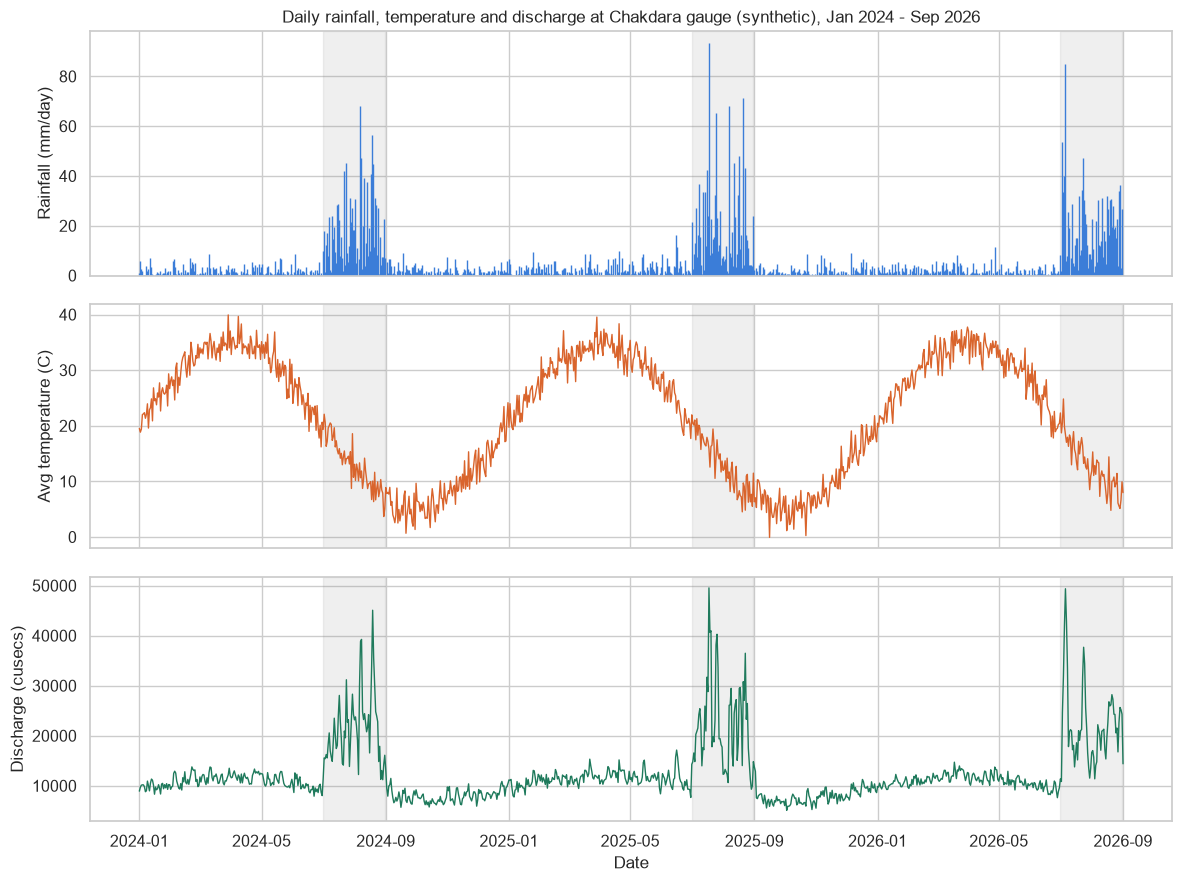

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].vlines(daily["date"], 0, daily["rainfall_mm"], color="#3b7dd8", lw=1)
axes[0].set_ylim(0)
axes[0].set_ylabel("Rainfall (mm/day)")
axes[0].set_title("Daily rainfall, temperature and discharge at Chakdara gauge (synthetic), Jan 2024 - Sep 2026")
axes[1].plot(daily["date"], daily["avg_temp_c"], color="#d9642c", lw=1)
axes[1].set_ylabel("Avg temperature (C)")
axes[2].plot(daily["date"], daily["discharge_cusecs"], color="#1f7a5c", lw=1)
axes[2].set_ylabel("Discharge (cusecs)")
axes[2].set_xlabel("Date")
for ax in axes:
    for y in [2024, 2025, 2026]:
        ax.axvspan(pd.Timestamp(y, 7, 1), pd.Timestamp(y, 8, 31), color="grey", alpha=0.12)
save("01_daily_series.png")

Grey bands are July-August. Rainfall switches on at 1 July and off at 31 August like a step, and discharge spikes follow it. Outside those two months discharge is a smooth wave. Temperature is a clean sine curve with noise.

In [14]:
monthly = daily.groupby("month").agg(
    days=("date", "size"),
    mean_rain=("rainfall_mm", "mean"),
    max_rain=("rainfall_mm", "max"),
    mean_temp=("avg_temp_c", "mean"),
    mean_discharge=("discharge_cusecs", "mean"),
    max_discharge=("discharge_cusecs", "max")).round(2)
monthly

,days,mean_rain,max_rain,mean_temp,mean_discharge,max_discharge
month,,,,,,
1,93,1.970,9.310,24.090,"10,188.750","13,073.600"
2,85,2.070,6.990,30.610,"11,174.060","13,771.200"
3,93,2.140,8.670,34.020,"11,900.870","15,315.300"
4,90,2.070,11.540,34.240,"11,886.190","15,166.800"
5,93,1.910,8.570,30.830,"11,164.450","15,119.600"
6,90,2.110,16.340,23.740,"10,221.360","17,133.800"
7,93,18.860,93.600,16.450,"22,270.230","49,542.500"
8,93,18.920,71.370,9.680,"21,409.350","45,077.700"
9,61,2.160,9.220,5.690,"7,945.280","14,389.900"


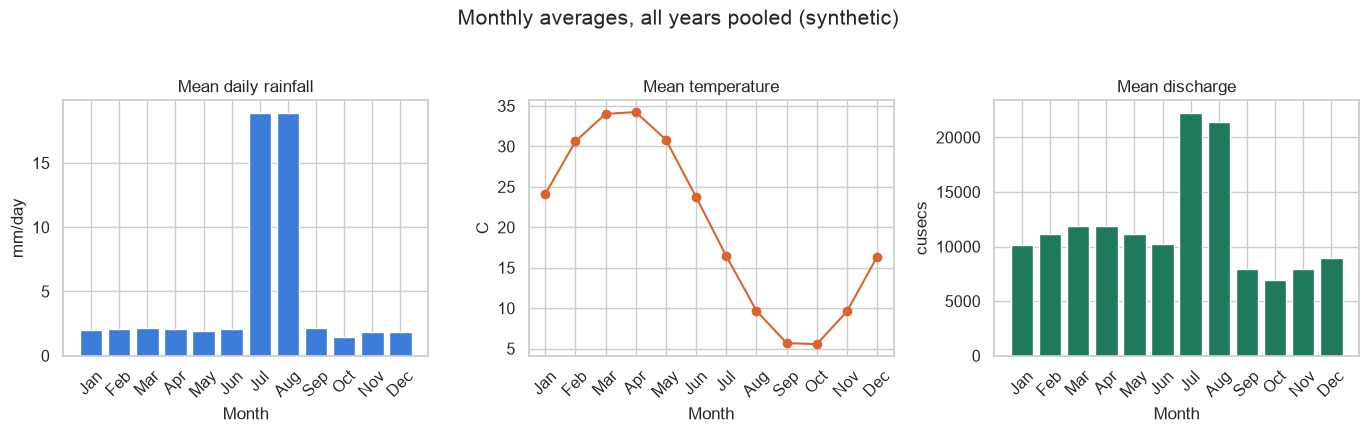

In [15]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].bar(month_names, monthly["mean_rain"], color="#3b7dd8")
axes[0].set_title("Mean daily rainfall"); axes[0].set_ylabel("mm/day")
axes[1].plot(month_names, monthly["mean_temp"], marker="o", color="#d9642c")
axes[1].set_title("Mean temperature"); axes[1].set_ylabel("C")
axes[2].bar(month_names, monthly["mean_discharge"], color="#1f7a5c")
axes[2].set_title("Mean discharge"); axes[2].set_ylabel("cusecs")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("Month")
fig.suptitle("Monthly averages, all years pooled (synthetic)", y=1.03)
save("02_monthly_profile.png")

The temperature cycle is the wrong way round for northern Pakistan. It peaks in March-April and bottoms out in September-October, with the July-August monsoon sitting at mid-to-low temperatures. In the real Swat valley June-July are the hottest months and January the coldest. This looks like a phase error in the generator, and it is the reason for the odd negative rain/temperature correlation further down. I would not use the temperature column for anything.

In [16]:
season = daily.groupby("monsoon").agg(
    days=("date", "size"),
    total_rain=("rainfall_mm", "sum"),
    mean_rain=("rainfall_mm", "mean"),
    median_rain=("rainfall_mm", "median"),
    mean_discharge=("discharge_cusecs", "mean"),
    max_discharge=("discharge_cusecs", "max")).round(2)
season["share_of_rain_pct"] = (season["total_rain"] / season["total_rain"].sum() * 100).round(1)
season

,days,total_rain,mean_rain,median_rain,mean_discharge,max_discharge,share_of_rain_pct
monsoon,,,,,,,
False,789,"1,561.590",1.980,1.380,"10,110.490","17,133.800",30.800
True,186,"3,513.670",18.890,14.690,"21,839.790","49,542.500",69.200


In [17]:
yearly = daily.groupby("year").agg(
    days=("date", "size"),
    total_rain=("rainfall_mm", "sum"),
    monsoon_rain=("rainfall_mm", lambda s: s[daily.loc[s.index, "monsoon"]].sum()),
    wettest_day=("rainfall_mm", "max"),
    mean_discharge=("discharge_cusecs", "mean"),
    peak_discharge=("discharge_cusecs", "max"),
    flood_days=("flood_label", "sum")).round(1)
yearly

,days,total_rain,monsoon_rain,wettest_day,mean_discharge,peak_discharge,flood_days
year,,,,,,,
2024,366,"1,713.100","1,145.000",68.000,"11,715.300","45,077.700",0
2025,365,"1,837.200","1,178.300",93.600,"12,015.700","49,542.500",0
2026,244,"1,525.000","1,190.300",85.100,"13,794.500","49,371.700",0


2026 only runs to 1 September, so its totals are not comparable with the other two years, although its monsoon months are complete.

## Distributions

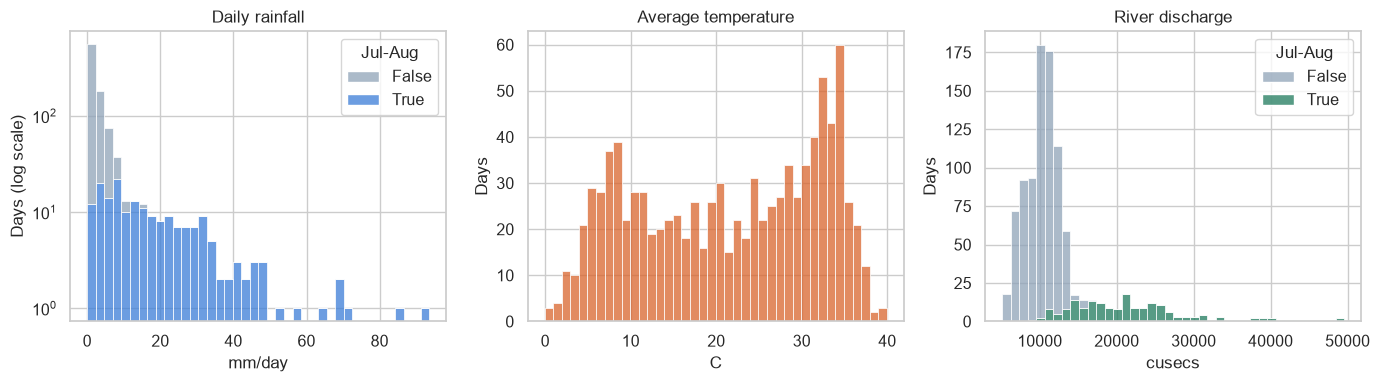

rainfall_mm         4.010
avg_temp_c         -0.190
discharge_cusecs    2.600
dtype: float64


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(daily, x="rainfall_mm", hue="monsoon", bins=40, ax=axes[0], palette=["#8fa3b8", "#3b7dd8"], multiple="stack")
axes[0].set_title("Daily rainfall"); axes[0].set_xlabel("mm/day"); axes[0].set_yscale("log")
axes[0].set_ylabel("Days (log scale)")
sns.histplot(daily, x="avg_temp_c", bins=40, ax=axes[1], color="#d9642c")
axes[1].set_title("Average temperature"); axes[1].set_xlabel("C"); axes[1].set_ylabel("Days")
sns.histplot(daily, x="discharge_cusecs", hue="monsoon", bins=40, ax=axes[2], palette=["#8fa3b8", "#1f7a5c"], multiple="stack")
axes[2].set_title("River discharge"); axes[2].set_xlabel("cusecs"); axes[2].set_ylabel("Days")
for ax in [axes[0], axes[2]]:
    ax.get_legend().set_title("Jul-Aug")
save("03_distributions.png")
print(daily[["rainfall_mm", "avg_temp_c", "discharge_cusecs"]].skew().round(2))

Rainfall is strongly right-skewed and the long tail is entirely monsoon days. Temperature is the flat, two-humped shape you get from sampling a sine wave. Discharge is two populations: a tight cluster for the ten ordinary months and a wide spread for July-August.

## Relationships

In [19]:
num_cols = ["rainfall_mm", "avg_temp_c", "discharge_cusecs", "water_level_m"]
corr = daily[num_cols].corr()
print(corr.round(3))
print("\nrain vs discharge, monsoon days only:", round(daily[daily.monsoon]["rainfall_mm"].corr(daily[daily.monsoon]["discharge_cusecs"]), 3))
print("rain vs discharge, other days:", round(daily[~daily.monsoon]["rainfall_mm"].corr(daily[~daily.monsoon]["discharge_cusecs"]), 3))

                  rainfall_mm  avg_temp_c  discharge_cusecs  water_level_m
rainfall_mm             1.000      -0.247             0.773          0.773
avg_temp_c             -0.247       1.000            -0.064         -0.064
discharge_cusecs        0.773      -0.064             1.000          1.000
water_level_m           0.773      -0.064             1.000          1.000

rain vs discharge, monsoon days only: 0.592
rain vs discharge, other days: 0.315


In [20]:
# does yesterday's rain matter, or only today's?
for lag in range(0, 6):
    r = daily["rainfall_mm"].shift(lag).corr(daily["discharge_cusecs"])
    print(f"rain lagged {lag} day(s) vs discharge: {r:.3f}")
print("discharge lag-1 autocorrelation:", round(daily["discharge_cusecs"].autocorr(1), 3))
print("rainfall lag-1 autocorrelation:", round(daily["rainfall_mm"].autocorr(1), 3))
for win in [2, 3, 4, 5]:
    r = daily["rainfall_mm"].rolling(win).sum().corr(daily["discharge_cusecs"])
    print(f"{win}-day rain total vs discharge: {r:.3f}")

rain lagged 0 day(s) vs discharge: 0.773
rain lagged 1 day(s) vs discharge: 0.763
rain lagged 2 day(s) vs discharge: 0.773
rain lagged 3 day(s) vs discharge: 0.525
rain lagged 4 day(s) vs discharge: 0.524
rain lagged 5 day(s) vs discharge: 0.498
discharge lag-1 autocorrelation: 0.885
rainfall lag-1 autocorrelation: 0.448
2-day rain total vs discharge: 0.902
3-day rain total vs discharge: 0.964
4-day rain total vs discharge: 0.921
5-day rain total vs discharge: 0.894


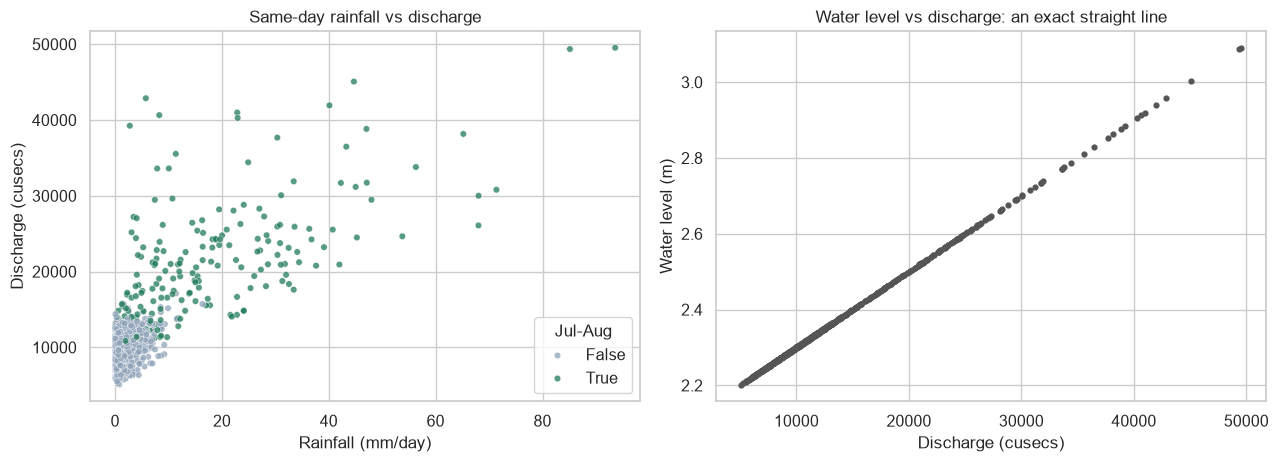

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=daily, x="rainfall_mm", y="discharge_cusecs", hue="monsoon", palette=["#8fa3b8", "#1f7a5c"], s=22, alpha=0.75, ax=axes[0])
axes[0].set_title("Same-day rainfall vs discharge")
axes[0].set_xlabel("Rainfall (mm/day)"); axes[0].set_ylabel("Discharge (cusecs)")
axes[0].get_legend().set_title("Jul-Aug")
axes[1].scatter(daily["discharge_cusecs"], daily["water_level_m"], s=12, color="#555555")
axes[1].set_title("Water level vs discharge: an exact straight line")
axes[1].set_xlabel("Discharge (cusecs)"); axes[1].set_ylabel("Water level (m)")
save("04_rain_discharge_level.png")

In [22]:
# rough fit for monsoon days to see how discharge responds to rain
m = daily[daily.monsoon]
b, a = np.polyfit(m["rainfall_mm"], m["discharge_cusecs"], 1)
print(f"monsoon days: discharge ~ {a:,.0f} + {b:,.0f} per mm of same-day rain")
o = daily[~daily.monsoon]
b2, a2 = np.polyfit(o["rainfall_mm"], o["discharge_cusecs"], 1)
print(f"other days:   discharge ~ {a2:,.0f} + {b2:,.0f} per mm of same-day rain")

monsoon days: discharge ~ 16,459 + 285 per mm of same-day rain
other days:   discharge ~ 9,487 + 315 per mm of same-day rain


Same-day rainfall and discharge move together (r about 0.77 overall). Rain from one and two days earlier correlates just as strongly and then the correlation drops sharply at three days, and the 3-day rain total tracks discharge better than any single day. That pattern suggests discharge was generated from a 3-day rainfall window on top of a seasonal base, though the README does not say how it was built. The negative rain/temperature correlation is just the misplaced temperature cycle. Water level vs discharge is r = 1.000 by construction.

## The yearly flood table

In [23]:
floods.drop(columns="Year").describe().T

,count,mean,std,min,25%,50%,75%,max
Peak_Discharge_Cusecs,17.000,"81,764.706","53,532.151","40,000.000","50,000.000","65,000.000","88,000.000","247,000.000"
Monsoon_Rainfall_Anomaly_Pct,17.000,12.706,21.757,-12.000,0.000,8.000,18.000,78.000
Flood_Occurred,17.000,0.235,0.437,0.000,0.000,0.000,0.000,1.000
Damages_PKR_Millions,17.000,"2,968.824","8,736.849",0.000,0.000,150.000,450.000,"35,000.000"


In [24]:
floods_sorted = floods.sort_values("Peak_Discharge_Cusecs", ascending=False)
floods_sorted

,Year,Peak_Discharge_Cusecs,Monsoon_Rainfall_Anomaly_Pct,Flood_Occurred,Damages_PKR_Millions
12,2022,247000,78,1,35000
0,2010,175000,45,1,12000
15,2025,98000,25,1,950
10,2020,95000,22,1,850
16,2026,88000,18,0,400
6,2016,85000,15,0,450
14,2024,75000,12,0,300
13,2023,70000,8,0,120
11,2021,65000,0,0,0
5,2015,60000,8,0,200


In [25]:
flood_years = floods[floods["Flood_Occurred"] == 1]
print("flood years:", flood_years["Year"].tolist())
print("lowest peak among flood years:", flood_years["Peak_Discharge_Cusecs"].min())
print("highest peak among non-flood years:", floods[floods["Flood_Occurred"] == 0]["Peak_Discharge_Cusecs"].max())
print("total damages (PKR m):", floods["Damages_PKR_Millions"].sum())
print("share from 2010 + 2022: %.1f%%" % (floods[floods["Year"].isin([2010, 2022])]["Damages_PKR_Millions"].sum() / floods["Damages_PKR_Millions"].sum() * 100))
print("years with zero damages:", (floods["Damages_PKR_Millions"] == 0).sum())
print("non-flood years with damages > 0:", ((floods["Flood_Occurred"] == 0) & (floods["Damages_PKR_Millions"] > 0)).sum())

flood years: [2010, 2020, 2022, 2025]
lowest peak among flood years: 95000
highest peak among non-flood years: 88000
total damages (PKR m): 50470
share from 2010 + 2022: 93.1%
years with zero damages: 6
non-flood years with damages > 0: 7


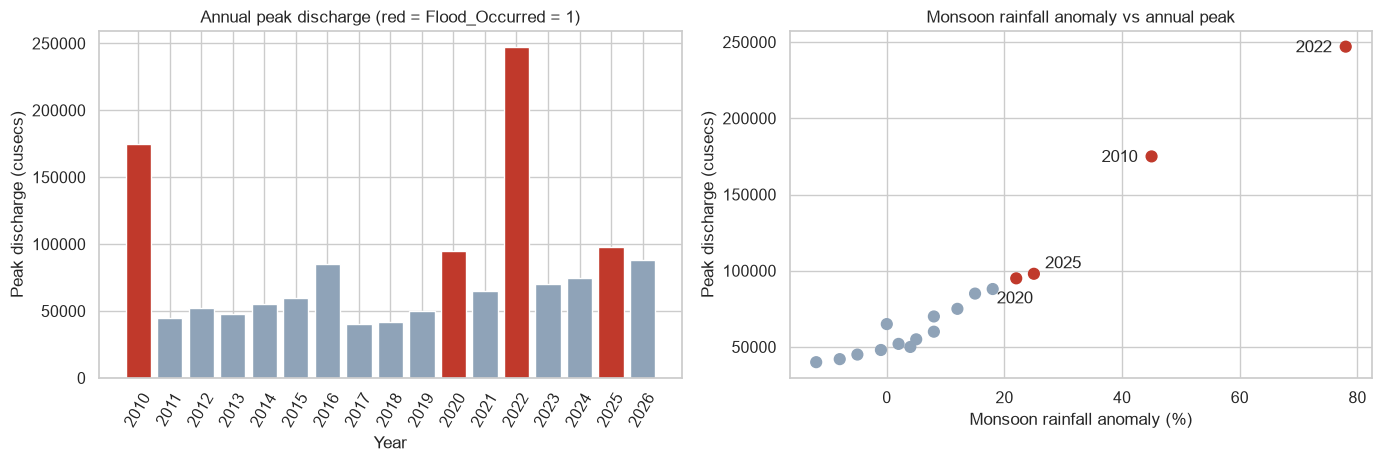

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colors = floods["Flood_Occurred"].map({1: "#c0392b", 0: "#8fa3b8"})
axes[0].bar(floods["Year"].astype(str), floods["Peak_Discharge_Cusecs"], color=colors)
axes[0].set_title("Annual peak discharge (red = Flood_Occurred = 1)")
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Peak discharge (cusecs)")
axes[0].tick_params(axis="x", rotation=60)
axes[1].scatter(floods["Monsoon_Rainfall_Anomaly_Pct"], floods["Peak_Discharge_Cusecs"], c=colors, s=60)
offsets = {2010: (-36, -4), 2022: (-36, -4), 2020: (-14, -18), 2025: (8, 4)}
for _, r in floods[floods["Flood_Occurred"] == 1].iterrows():
    axes[1].annotate(int(r["Year"]), (r["Monsoon_Rainfall_Anomaly_Pct"], r["Peak_Discharge_Cusecs"]), textcoords="offset points", xytext=offsets[int(r["Year"])])
axes[1].set_title("Monsoon rainfall anomaly vs annual peak")
axes[1].set_xlabel("Monsoon rainfall anomaly (%)"); axes[1].set_ylabel("Peak discharge (cusecs)")
save("05_flood_table.png")

Four of the 17 years are flagged as floods: 2010, 2020, 2022 and 2025. In this table the flag lines up exactly with a peak of 95,000 cusecs or more, and peak discharge rises almost in step with the rainfall anomaly. With 17 hand-built rows that is a description of how the table was put together, not a tested relationship, so no statistics from it. The 2026 row is also odd for a "historical" table given the daily file ends in September 2026.

## Daily series vs the flood table (2024-2026)

The two files overlap for three years. If they described the same river, the largest daily discharge in a year should be close to that year's listed peak.

In [27]:
overlap = yearly[["peak_discharge", "flood_days"]].join(floods.set_index("Year")[["Peak_Discharge_Cusecs", "Monsoon_Rainfall_Anomaly_Pct", "Flood_Occurred"]])
overlap = overlap.rename(columns={"peak_discharge": "daily_file_max", "Peak_Discharge_Cusecs": "flood_table_peak", "flood_days": "daily_flood_label_days"})
overlap["daily_as_pct_of_table"] = (overlap["daily_file_max"] / overlap["flood_table_peak"] * 100).round(1)
overlap["monsoon_rain_mm"] = yearly["monsoon_rain"]
overlap["peak_date"] = daily.loc[daily.groupby("year")["discharge_cusecs"].idxmax(), ["year", "date"]].set_index("year")["date"].dt.date
overlap

,daily_file_max,daily_flood_label_days,flood_table_peak,Monsoon_Rainfall_Anomaly_Pct,Flood_Occurred,daily_as_pct_of_table,monsoon_rain_mm,peak_date
year,,,,,,,,
2024,"45,077.700",0,75000,12,0,60.100,"1,145.000",2024-08-19
2025,"49,542.500",0,98000,25,1,50.600,"1,178.300",2025-07-18
2026,"49,371.700",0,88000,18,0,56.100,"1,190.300",2026-07-06


In [28]:
print("days at or above 95,000 cusecs in the daily file:", (daily["discharge_cusecs"] >= 95000).sum())
print("days at or above 40,000 cusecs:", (daily["discharge_cusecs"] >= 40000).sum())
mean_monsoon = overlap["monsoon_rain_mm"].mean()
print("monsoon rain vs 3-year mean (%):", ((overlap["monsoon_rain_mm"] / mean_monsoon - 1) * 100).round(1).to_dict())

days at or above 95,000 cusecs in the daily file: 0
days at or above 40,000 cusecs: 8
monsoon rain vs 3-year mean (%): {2024: -2.2, 2025: 0.6, 2026: 1.6}


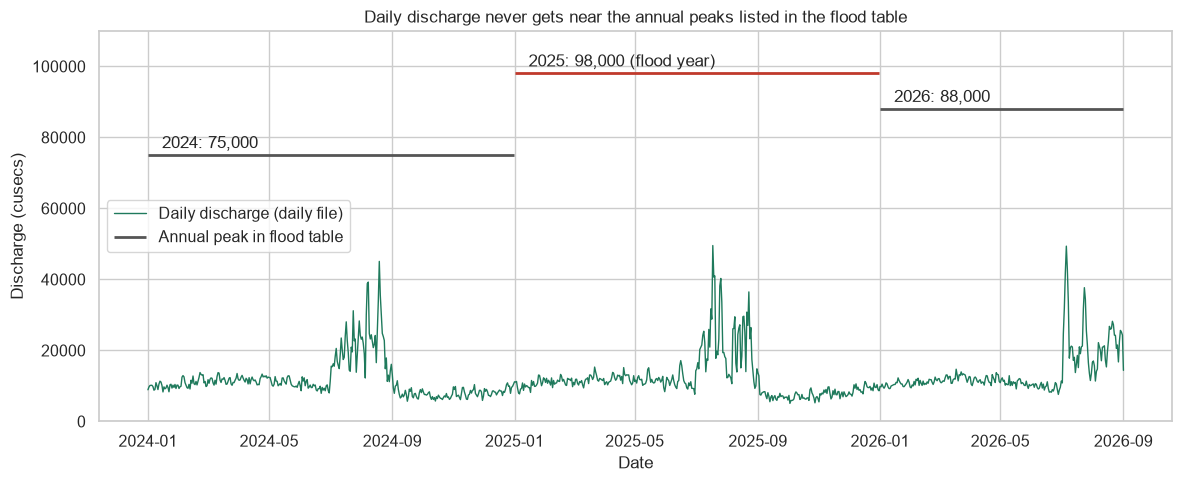

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily["date"], daily["discharge_cusecs"], color="#1f7a5c", lw=1, label="Daily discharge (daily file)")
for i, (y, r) in enumerate(overlap.iterrows()):
    end = min(pd.Timestamp(y, 12, 31), daily["date"].max())
    ax.hlines(r["flood_table_peak"], pd.Timestamp(y, 1, 1), end, color="#c0392b" if r["Flood_Occurred"] == 1 else "#555555", lw=2,
              label="Annual peak in flood table" if i == 0 else None)
    ax.text(pd.Timestamp(y, 1, 15), r["flood_table_peak"] + 2000, f"{y}: {int(r['flood_table_peak']):,}" + (" (flood year)" if r["Flood_Occurred"] == 1 else ""))
ax.set_ylim(0, 110000)
ax.set_title("Daily discharge never gets near the annual peaks listed in the flood table")
ax.set_xlabel("Date"); ax.set_ylabel("Discharge (cusecs)")
ax.legend(loc="center left")
save("06_daily_vs_flood_table.png")

They do not agree. The daily maximum is 50 to 60 percent of the listed annual peak in each year, and 2025, the one overlapping year flagged as a flood, has no flood-labelled day in the daily file. The table also gives 2024-2026 monsoon rainfall anomalies of +12, +25 and +18 percent, while the July-August rain totals in the daily file are within about 2 percent of each other (the anomaly baseline is not documented, so this is only a rough comparison). The two files look like they were generated separately. So the daily series cannot be used to study the listed flood events, and I am not going to pretend it shows them.

## Basin features

                Sub_Basin  Elevation_Mean_m  Avg_Slope_Degrees  Forest_Cover_Pct  Encroachment_Index_1to10
       Upper Swat (Kalam)              2500                 32                35                         2
Mid Swat (Madyan/Bahrain)              1600                 24                22                         5
     Lower Swat (Mingora)               950                 12                11                         9
      Chakdara Downstream               680                  5                 6                         7


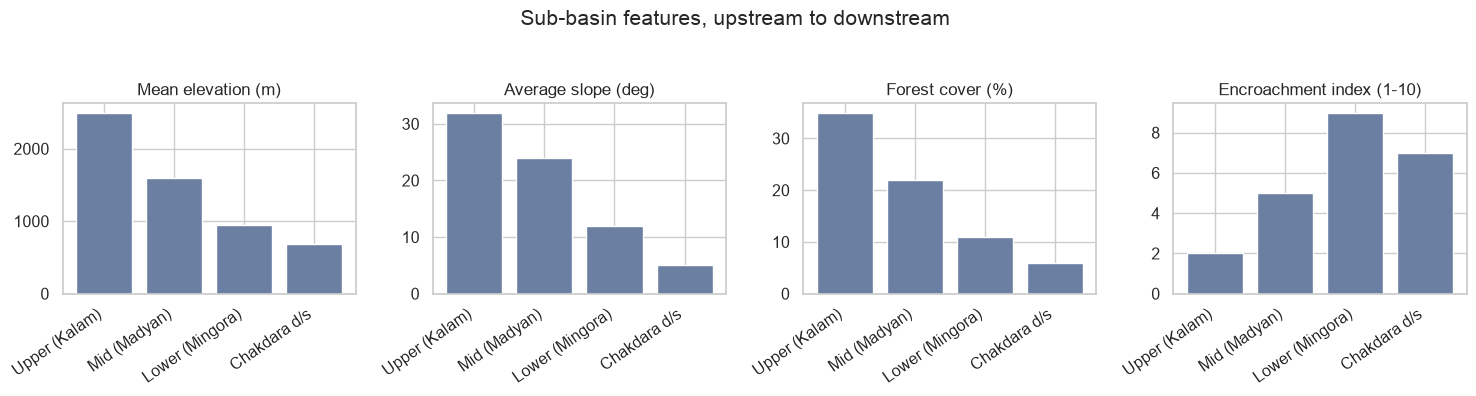

In [30]:
print(basin.to_string(index=False))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
short = ["Upper (Kalam)", "Mid (Madyan)", "Lower (Mingora)", "Chakdara d/s"]
cols = [("Elevation_Mean_m", "Mean elevation (m)"), ("Avg_Slope_Degrees", "Average slope (deg)"),
        ("Forest_Cover_Pct", "Forest cover (%)"), ("Encroachment_Index_1to10", "Encroachment index (1-10)")]
for ax, (c, title) in zip(axes, cols):
    ax.bar(short, basin[c], color="#6b7fa3")
    ax.set_title(title)
    ax.set_xticks(range(len(short)), short, rotation=35, ha="right")
fig.suptitle("Sub-basin features, upstream to downstream", y=1.04)
save("07_basin_features.png")

Four rows, ordered upstream to downstream. Elevation, slope and forest cover all fall going downstream. The encroachment index is highest at Lower Swat (Mingora), not at the lowest point. How the index was scored is not documented. There is no key linking these rows to the daily file beyond the gauge being called Chakdara.

## Highest / lowest / most

In [31]:
def row(label, r, col, fmt):
    print(f"{label}: {fmt.format(r[col])} on {r['date'].date()}")

row("Wettest day", daily.loc[daily["rainfall_mm"].idxmax()], "rainfall_mm", "{:.2f} mm")
row("Driest day", daily.loc[daily["rainfall_mm"].idxmin()], "rainfall_mm", "{:.2f} mm")
row("Highest discharge", daily.loc[daily["discharge_cusecs"].idxmax()], "discharge_cusecs", "{:,.1f} cusecs")
row("Lowest discharge", daily.loc[daily["discharge_cusecs"].idxmin()], "discharge_cusecs", "{:,.1f} cusecs")
row("Highest water level", daily.loc[daily["water_level_m"].idxmax()], "water_level_m", "{:.3f} m")
row("Lowest water level", daily.loc[daily["water_level_m"].idxmin()], "water_level_m", "{:.3f} m")
row("Hottest day", daily.loc[daily["avg_temp_c"].idxmax()], "avg_temp_c", "{:.2f} C")
row("Coldest day", daily.loc[daily["avg_temp_c"].idxmin()], "avg_temp_c", "{:.2f} C")

ym = daily.groupby(["year", "month"]).agg(rain=("rainfall_mm", "sum"), q=("discharge_cusecs", "mean"), n=("date", "size"))
ym = ym[ym["n"] >= 28]
ym.index = [f"{y}-{m:02d}" for y, m in ym.index]
print("Wettest calendar month:", ym["rain"].idxmax(), f"{ym['rain'].max():.1f} mm")
print("Driest full calendar month:", ym["rain"].idxmin(), f"{ym['rain'].min():.1f} mm")
print("Highest mean monthly discharge:", ym["q"].idxmax(), f"{ym['q'].max():,.0f} cusecs")
print("Lowest mean monthly discharge:", ym["q"].idxmin(), f"{ym['q'].min():,.0f} cusecs")
print("Days with 50 mm or more of rain:", (daily["rainfall_mm"] >= 50).sum(), "| all in Jul-Aug:", daily[daily["rainfall_mm"] >= 50]["monsoon"].all())
print("Largest one-day rise in discharge:", f"{daily['discharge_cusecs'].diff().max():,.0f} cusecs on", daily.loc[daily['discharge_cusecs'].diff().idxmax(), 'date'].date())
print()
top = floods.loc[floods["Peak_Discharge_Cusecs"].idxmax()]
low = floods.loc[floods["Peak_Discharge_Cusecs"].idxmin()]
print(f"Flood table, highest peak: {top['Year']} with {top['Peak_Discharge_Cusecs']:,} cusecs, anomaly {top['Monsoon_Rainfall_Anomaly_Pct']}%, damages PKR {top['Damages_PKR_Millions']:,} m")
print(f"Flood table, lowest peak: {low['Year']} with {low['Peak_Discharge_Cusecs']:,} cusecs, anomaly {low['Monsoon_Rainfall_Anomaly_Pct']}%")
print("Flood table, ratio of highest to lowest peak:", round(top["Peak_Discharge_Cusecs"] / low["Peak_Discharge_Cusecs"], 2))
print("Basin, steepest:", basin.loc[basin["Avg_Slope_Degrees"].idxmax(), "Sub_Basin"], "| most encroached:", basin.loc[basin["Encroachment_Index_1to10"].idxmax(), "Sub_Basin"],
      "| least forest:", basin.loc[basin["Forest_Cover_Pct"].idxmin(), "Sub_Basin"])

Wettest day: 93.60 mm on 2025-07-18
Driest day: 0.01 mm on 2024-03-13
Highest discharge: 49,542.5 cusecs on 2025-07-18
Lowest discharge: 5,089.7 cusecs on 2025-10-03
Highest water level: 3.091 m on 2025-07-18
Lowest water level: 2.202 m on 2025-10-03
Hottest day: 39.93 C on 2024-03-29
Coldest day: -0.07 C on 2025-09-16
Wettest calendar month: 2024-08 652.8 mm
Driest full calendar month: 2026-06 42.8 mm
Highest mean monthly discharge: 2025-07 24,148 cusecs
Lowest mean monthly discharge: 2025-10 6,868 cusecs
Days with 50 mm or more of rain: 8 | all in Jul-Aug: True
Largest one-day rise in discharge: 20,728 cusecs on 2025-07-18

Flood table, highest peak: 2022 with 247,000 cusecs, anomaly 78%, damages PKR 35,000 m
Flood table, lowest peak: 2017 with 40,000 cusecs, anomaly -12%
Flood table, ratio of highest to lowest peak: 6.18
Basin, steepest: Upper Swat (Kalam) | most encroached: Lower Swat (Mingora) | least forest: Chakdara Downstream


In [32]:
daily.nlargest(5, 'discharge_cusecs')[['date', 'rainfall_mm', 'avg_temp_c', 'discharge_cusecs', 'water_level_m']]

,date,rainfall_mm,avg_temp_c,discharge_cusecs,water_level_m
564,2025-07-18,93.600,15.860,"49,542.500",3.091
917,2026-07-06,85.130,18.480,"49,371.700",3.087
231,2024-08-19,44.700,10.050,"45,077.700",3.002
918,2026-07-07,5.750,17.020,"42,875.900",2.958
916,2026-07-05,40.110,19.850,"41,934.900",2.939


## Findings

- The dataset is synthetic by its own README, and it shows: no gaps, no dry days, a water level that is an exact linear function of discharge, and a temperature cycle that is out of phase with the real climate.
- The daily file is 975 consecutive days (1 Jan 2024 to 1 Sep 2026) for a single gauge.
- Rainfall is a two-level process: about 2 mm/day for ten months and about 19 mm/day in July-August. Those 62 days a year carry well over half of all the rain.
- Discharge follows a smooth seasonal wave plus a same-day response to rain. Every reading above 40,000 cusecs is in July or August.
- `Flood_Label` is zero on all 975 days, so the classification target the README advertises does not exist in this file.
- The yearly flood table and the daily series are inconsistent in the three years they share: daily maxima are 50 to 60 percent of the listed annual peaks, and the 2025 flood year has no flood day.
- In the flood table, the flag coincides exactly with peaks of 95,000 cusecs or more, and 2010 and 2022 account for nearly all listed damages.

## Limitations

- Simulated data. None of the numbers should be quoted as facts about the Swat River or about real floods.
- One station, under three years, and one of those years is partial.
- The flood table has 17 rows and the basin table 4. They are described, not analysed statistically.
- The temperature column appears to be mis-phased and the water level column is redundant.
- With no positive flood labels, nothing here can train or validate a flood classifier. A discharge regression would mostly be relearning the generator's formula.